In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

tf.keras.utils.set_random_seed(42)

DATA_PATH = "/app/data/processed/dataset.npz"
MODEL_PATH = "/app/models/best_model.h5"

I0000 00:00:1792162473.582496    2007 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792162473.583423    2007 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792162473.893132    2007 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792162476.136020    2007 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
data = np.load(DATA_PATH)

X_train = data["X_train"].astype("float32") / 255.0
y_train = data["y_train"]
X_val = data["X_val"].astype("float32") / 255.0
y_val = data["y_val"]
X_test = data["X_test"].astype("float32") / 255.0
y_test = data["y_test"]
class_named = data["class_named"]

input_shape = X_train.shape[1:]
num_classes = len(class_named)

print("X_train:", X_train.shape, X_train.dtype, X_train.max())
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
print("Classes:", class_named)

X_train: (4775, 224, 224, 3) float32 1.0
X_val:   (843, 224, 224, 3)
X_test:  (1405, 224, 224, 3)
Classes: ['glioma' 'meningioma' 'notumor' 'pituitary']


In [3]:
model = Sequential([
    Input(shape=input_shape),
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(num_classes, activation="softmax")
])

E0000 00:00:1792162493.994886    2007 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,948 (49.36 MB)

 Trainable params: 12,938,948 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
checkpoint = ModelCheckpoint(
    filepath=MODEL_PATH,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

callbacks = [checkpoint, early_stop]

In [6]:
import json

start_time = time.time()

history = model.fit(
    X_train, y_train,
    batch_size=32,
    epochs=30,
    validation_data=(X_val, y_val),
    callbacks=callbacks
)

duration = time.time() - start_time
print(f"Training time: {duration/60:.1f} minutes")
print(f"Epochs run: {len(history.history['loss'])}")

with open("/app/models/history.json", "w") as f:
    json.dump(history.history, f)

Epoch 1/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step - accuracy: 0.7064 - loss: 0.7110
Epoch 1: val_loss improved from None to 0.54647, saving model to /app/models/best_model.h5



Epoch 1: finished saving model to /app/models/best_model.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 47s 301ms/step - accuracy: 0.7064 - loss: 0.7110 - val_accuracy: 0.7746 - val_loss: 0.5465
Epoch 2/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.8553 - loss: 0.3809
Epoch 2: val_loss improved from 0.54647 to 0.33153, saving model to /app/models/best_model.h5



Epoch 2: finished saving model to /app/models/best_model.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 54s 359ms/step - accuracy: 0.8553 - loss: 0.3809 - val_accuracy: 0.8885 - val_loss: 0.3315
Epoch 3/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step - accuracy: 0.9032 - loss: 0.2524
Epoch 3: val_loss improved from 0.33153 to 0.24686, saving model to /app/models/best_model.h5



Epoch 3: finished saving model to /app/models/best_model.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 54s 362ms/step - accuracy: 0.9032 - loss: 0.2524 - val_accuracy: 0.9098 - val_loss: 0.2469
Epoch 4/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step - accuracy: 0.9349 - loss: 0.1796
Epoch 4: val_loss improved from 0.24686 to 0.19171, saving model to /app/models/best_model.h5



Epoch 4: finished saving model to /app/models/best_model.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 53s 357ms/step - accuracy: 0.9349 - loss: 0.1796 - val_accuracy: 0.9217 - val_loss: 0.1917
Epoch 5/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.9581 - loss: 0.1297
Epoch 5: val_loss did not improve from 0.19171
150/150 ━━━━━━━━━━━━━━━━━━━━ 53s 351ms/step - accuracy: 0.9581 - loss: 0.1297 - val_accuracy: 0.9371 - val_loss: 0.1975
Epoch 6/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step - accuracy: 0.9646 - loss: 0.0897
Epoch 6: val_loss did not improve from 0.19171
150/150 ━━━━━━━━━━━━━━━━━━━━ 54s 360ms/step - accuracy: 0.9646 - loss: 0.0897 - val_accuracy: 0.9217 - val_loss: 0.2064
Epoch 7/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - accuracy: 0.9734 - loss: 0.0742
Epoch 7: val_loss improved from 0.19171 to 0.16617, saving model to /app/models/best_model.h5



Epoch 7: finished saving model to /app/models/best_model.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 54s 361ms/step - accuracy: 0.9734 - loss: 0.0742 - val_accuracy: 0.9383 - val_loss: 0.1662
Epoch 8/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step - accuracy: 0.9820 - loss: 0.0480
Epoch 8: val_loss improved from 0.16617 to 0.15048, saving model to /app/models/best_model.h5



Epoch 8: finished saving model to /app/models/best_model.h5
150/150 ━━━━━━━━━━━━━━━━━━━━ 55s 369ms/step - accuracy: 0.9820 - loss: 0.0480 - val_accuracy: 0.9549 - val_loss: 0.1505
Epoch 9/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - accuracy: 0.9883 - loss: 0.0341
Epoch 9: val_loss did not improve from 0.15048
150/150 ━━━━━━━━━━━━━━━━━━━━ 52s 345ms/step - accuracy: 0.9883 - loss: 0.0341 - val_accuracy: 0.9514 - val_loss: 0.1716
Epoch 10/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.9832 - loss: 0.0485
Epoch 10: val_loss did not improve from 0.15048
150/150 ━━━━━━━━━━━━━━━━━━━━ 52s 348ms/step - accuracy: 0.9832 - loss: 0.0485 - val_accuracy: 0.9514 - val_loss: 0.2103
Epoch 11/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.9887 - loss: 0.0375
Epoch 11: val_loss did not improve from 0.15048
150/150 ━━━━━━━━━━━━━━━━━━━━ 53s 351ms/step - accuracy: 0.9887 - loss: 0.0375 - val_accuracy: 0.9609 - val_loss: 0.1716
Epoch 12/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/

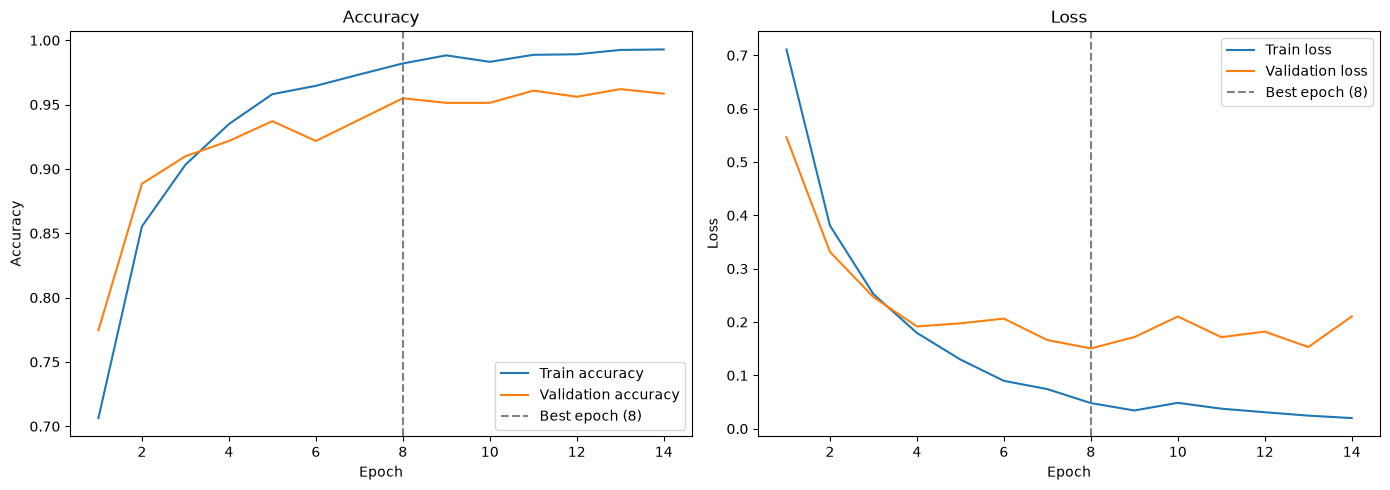

In [7]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(acc) + 1)
best_epoch = int(np.argmin(val_loss)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, acc, label="Train accuracy")
axes[0].plot(epochs_range, val_acc, label="Validation accuracy")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(epochs_range, loss, label="Train loss")
axes[1].plot(epochs_range, val_loss, label="Validation loss")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("/app/models/learning_curves.png", dpi=150)
plt.show()

Key Metrics at Epoch 8:

Training Accuracy: 98.20%

Validation Accuracy: 95.49%

Training Loss: 0.0480

Validation Loss: 0.1505

In [8]:
from tensorflow.keras.models import load_model

best_model = load_model(MODEL_PATH)

test_loss, test_acc = best_model.evaluate(X_test, y_test, batch_size=32, verbose=1)

print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.9651 - loss: 0.1598
Test loss:     0.1598
Test accuracy: 0.9651


44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step


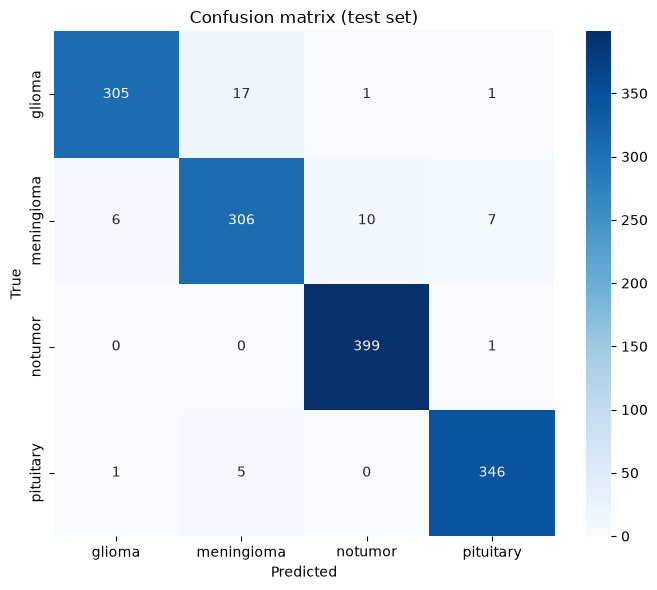

              precision    recall  f1-score   support

      glioma      0.978     0.941     0.959       324
  meningioma      0.933     0.930     0.932       329
     notumor      0.973     0.998     0.985       400
   pituitary      0.975     0.983     0.979       352

    accuracy                          0.965      1405
   macro avg      0.965     0.963     0.964      1405
weighted avg      0.965     0.965     0.965      1405



In [9]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_prob = best_model.predict(X_test, batch_size=32)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred)


plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_named, yticklabels=class_named)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.savefig("/app/models/confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_true, y_pred, target_names=class_named, digits=3))

Correct: 1356 | Wrong: 49


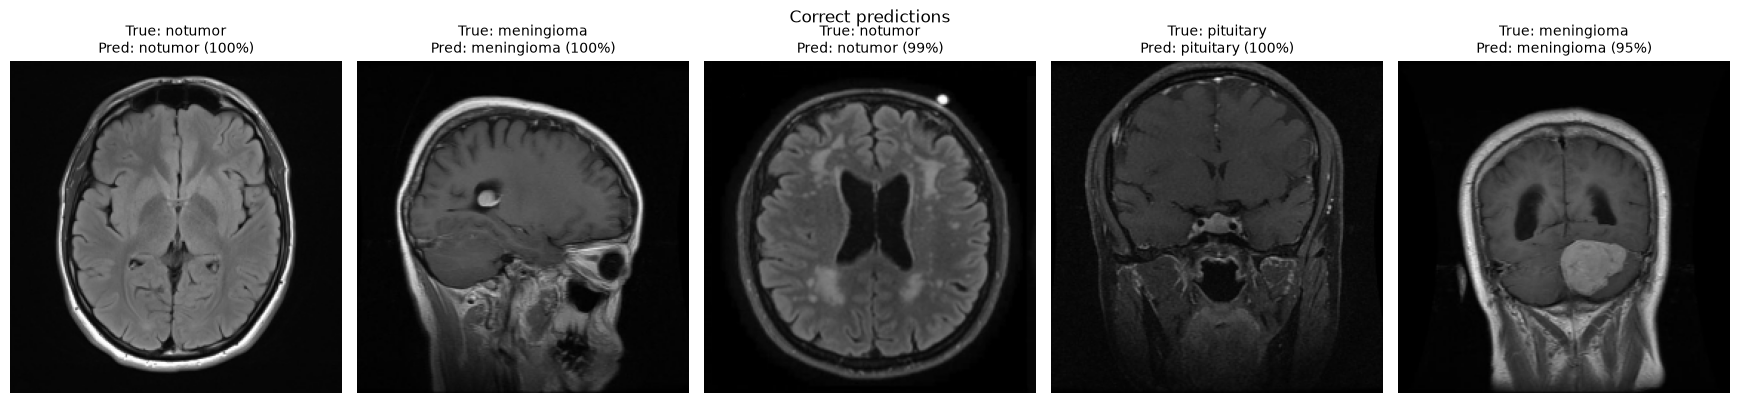

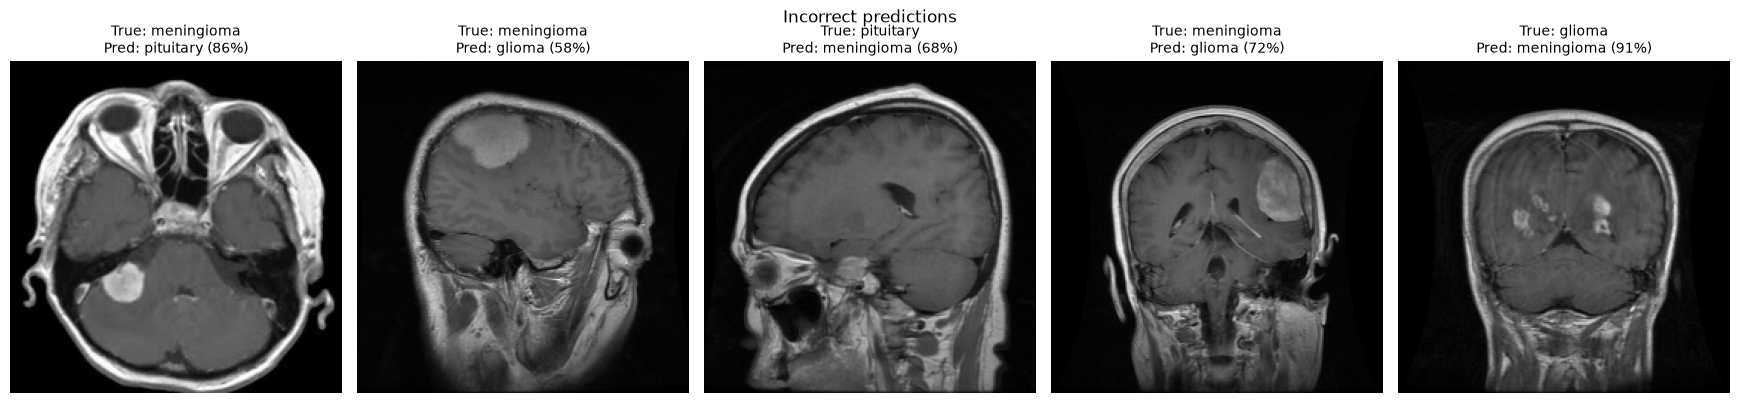

In [ ]:
rng = np.random.default_rng(42)

correct_idx = np.where(y_pred == y_true)[0]
wrong_idx = np.where(y_pred != y_true)[0]

print("Correct:", len(correct_idx), "| Wrong:", len(wrong_idx))

def show_examples(indexes, title, n=5):
    n = min(n, len(indexes))
    chosen = rng.choice(indexes, size=n, replace=False)
    plt.figure(figsize=(3.5 * n, 4.2))
    for k, i in enumerate(chosen):
        plt.subplot(1, n, k + 1)
        plt.imshow(X_test[i])
        confidence = y_prob[i].max() * 100
        plt.title(f"True: {class_named[y_true[i]]}\nPred: {class_named[y_pred[i]]} ({confidence:.0f}%)",
                  fontsize=10)
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"/app/models/{title.replace(' ', '_').lower()}.png", dpi=150)
    plt.show()

show_examples(correct_idx, "Correct predictions")
show_examples(wrong_idx, "Incorrect predictions")